In [1]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features 


In [12]:
# Selection des données
catalogue = data.catalogue          # DataFrame indexé par nom lisible
charger = data.charger              # Fonction de chargement de données

"""
# Sélection du dataset
# DE + FE full
selection = data.selectionner(sources=("12kDE","12kFE",),
                                  defauts=("IR", "B", "OR"),
                                  diametres=(7, 14,21, ),
                                  positions_or=("6",),
                                  charges=(0, 1, 2, 3),
                                  avec_sains=True)

# Ancien : toujours possible
table = features.construire_table(selection, charger, canaux=("DE",))
"""

# selection = data.selectionner2(sources=("12kDE", "12kFE", "Normal"), canaux=("DE", "FE"))
selection = data.selectionner2(
    sources=("12kDE", "12kFE", "Normal"),
    canaux={"12kDE": ("DE",), 
            "12kFE": ("FE",), 
            "Normal": ("DE",)},
)

table = features.construire_table2(selection, charger)     # canaux lus automatiquement

AssertionError: canal inconnu : {'12kDE': ('DE',), '12kFE': ('FE',), 'Normal': ('DE',)} (attendu DE/FE/BA)

In [3]:
# Construction dataset
# table = features.construire_table(selection, charger, canaux=("DE", "FE"))
# features.sauvegarder_table(table)                # écrit data/features/table_indicateurs.csv

INDICATEURS = indicateurs.COLONNES_TEMPORELS   # 4 indicateurs temporels (partie exploratoire)
# ORDRE = ["Sain", "IR007", "IR014", "IR021", "B007", "B014", "B021", "OR007", "OR014", "OR021"]


In [4]:
# Visu dataset
# table.iloc[70:100, :15]
table[table["canal"] == "FE"]

# display(table.groupby(["source", "classe", "canal"]).size().unstack())
# table.defaut.unique()

,fichier,fenetre,rpm,canal,numero,source,fs,defaut,position_OR,diametre_mils,...,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF,f_pic,classe
101,Normal_L0,0,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001018,0.006267,0.005233,0.006086,0.203094,0.285649,0.133188,0.378069,60.058594,Sain
102,Normal_L0,1,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001319,0.004294,0.006015,0.006202,0.154014,0.332968,0.194814,0.318204,60.791016,Sain
103,Normal_L0,2,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000574,0.007760,0.007006,0.005637,0.067372,0.160511,0.171577,0.600541,60.058594,Sain
104,Normal_L0,3,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000867,0.003905,0.011645,0.013029,0.251415,0.253171,0.209546,0.285868,30.761719,Sain
105,Normal_L0,4,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000781,0.008527,0.009871,0.011672,0.199272,0.142502,0.173827,0.484400,31.494141,Sain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8017,12kFE_OR021at6_L0,45,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.063823,0.056750,0.586948,0.669555,0.109431,0.541788,0.284245,0.064536,30.029297,OR021
8018,12kFE_OR021at6_L0,46,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.028864,0.029306,0.318542,0.330890,0.199736,0.660242,0.098169,0.041853,91.552734,OR021
8019,12kFE_OR021at6_L0,47,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.022011,0.019165,0.560075,0.656948,0.174760,0.494200,0.310677,0.020363,30.029297,OR021
8020,12kFE_OR021at6_L0,48,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.047168,0.030995,0.583986,0.674855,0.110190,0.549091,0.306058,0.034660,30.029297,OR021


In [5]:
# Preparation pour le modeling
#| label: preparation-modeling
#| code-summary: "Split par fichier + standardisation"
#| tbl-cap: "Répartition des fichiers entre apprentissage et test."

COLONNES_INDICATEURS = indicateurs.COLONNES_INDICATEURS
# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling(table, COLONNES_INDICATEURS)
X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, COLONNES_INDICATEURS, canal_train="DE", canal_test="FE", target="defaut")

print("##########################################")
print("######### Table d'apprentissage ##########")
print("##########################################")
print("1. Split Train => DE, Test => FE")
print("2. Répartition des classes du train")

# Équilibre UNIQUEMENT le train (le test reste complet)
X_train, y_train, X_test, y_test = features.equilibrer(X_train, y_train, X_test, y_test, type="train")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

print("##########################################")
print("############### Features #################")
print("##########################################")
X_train.head()

##########################################
######### Table d'apprentissage ##########
##########################################
1. Split Train => DE, Test => FE
2. Répartition des classes du train


,train,test
defaut,,
Sain,601,706
IR,601,600
B,601,600
OR,601,300


##########################################
############### Features #################
##########################################


,RMS,Pic,Crete,Kurtosis,amp_BPFI_1,amp_BPFI_2,amp_BPFI_3,amp_BPFO_1,amp_BPFO_2,amp_BPFO_3,...,amp_BSF_2,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF,f_pic
780,-0.847735,-0.781768,-0.780604,-0.650465,-0.725800,-0.725966,-0.603650,-0.565136,-0.585202,-0.725911,...,-0.919308,-0.601615,-0.787837,-0.652614,-0.651592,-0.224303,-0.913742,1.224345,0.671216,-0.556168
81,-0.796443,-0.779470,-0.980288,-0.686600,-0.730638,-0.716700,-0.596515,-0.548613,-0.576415,-0.716646,...,-0.761304,-0.616449,-0.659176,-0.539195,-0.549444,-1.142964,-0.212722,-0.232075,1.838096,-0.551642
77,-0.783754,-0.777603,-1.009861,-0.688146,-0.725264,-0.723930,-0.599593,-0.549732,-0.578699,-0.723875,...,-0.931533,-0.596463,-0.671538,-0.531648,-0.538230,-0.961148,-0.304105,0.019669,1.573235,-0.551642
309,-0.822640,-0.769992,-0.777564,-0.670050,-0.730716,-0.725472,-0.609288,-0.561481,-0.574960,-0.725417,...,-0.936464,-0.629029,-0.732258,-0.625770,-0.626069,-0.923070,-0.752710,0.543722,1.751643,-0.556168
621,-0.841750,-0.743998,-0.405766,-0.629525,-0.731696,-0.735625,-0.580797,-0.565026,-0.573764,-0.735569,...,-0.864944,-0.626332,-0.783576,-0.643557,-0.643883,-0.620246,-0.757983,0.732337,1.266960,-0.556168


In [6]:
#| label: regression logistique
from sklearn import linear_model

logreg = linear_model.LogisticRegression(max_iter=500, random_state=24)
logregb = linear_model.LogisticRegression(max_iter=500, random_state=24, class_weight="balanced") ##  >> Pour gérer le déséquilibre de classes

logreg.fit(X_train, y_train)
logregb.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_predb = logregb.predict(X_test)
cm = pd.crosstab(y_test, y_pred, rownames=['Classe réelle'], colnames=['Classe prédite'])
cmb = pd.crosstab(y_test, y_predb, rownames=['Classe réelle'], colnames=['Classe prédite'])

Classe prédite    B   IR   OR  Sain
Classe réelle                      
B               506    5   63    26
IR              338  262    0     0
OR               43   47  210     0
Sain              0    0    0   706


   ############## cmb
 Classe prédite    B   IR   OR  Sain
Classe réelle                      
B               506    5   63    26
IR              338  262    0     0
OR               43   47  210     0
Sain              0    0    0   706


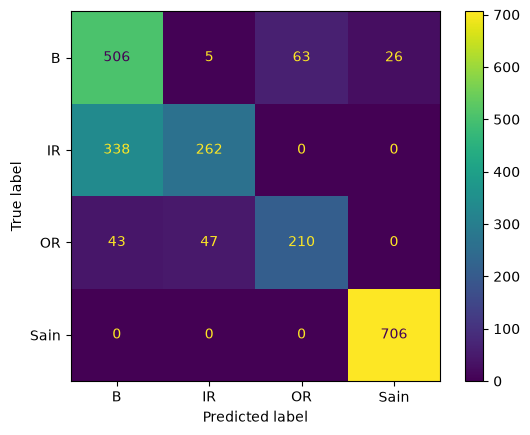

In [7]:
print(cm)
print("\n\n   ############## cmb\n", cmb)
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test)
plt.show()